# Model SPK Pemilihan Tanaman — TOPSIS & Fuzzy Weighted Product (Versi Final)

Implementasi final dari artikel *Sistem Pendukung Keputusan Pemilihan Tanaman Berbasis Data Cuaca Real-Time dengan TOPSIS dan Weighted Product*.
Setiap bagian diberi label persamaan/subbab artikel agar 100% sinkron dengan naskah, perhitungan manual Excel, dan sistem web Laravel.

| Bagian notebook | Subbab / Persamaan artikel |
|---|---|
| 1. Parameter | Tabel 3 |
| 2. Data & pra-pemrosesan | 2.1, 2.2, Tabel 1–2 |
| 3. Agregasi cuaca (Open-Meteo) | Pers. (1)–(2) |
| 4. Bobot Random Forest | 2.3, Pers. (3) |
| 5. Kesesuaian Gaussian | 2.4, Pers. (4) |
| 6. TOPSIS (dengan pengaman $\varepsilon$) | 2.5, Pers. (5)–(9) |
| 7. Fuzzy Weighted Product | 2.6, Pers. (10)–(11) |
| 8. Metrik & Cross-Validation | 2.7, Pers. (12)–(15) |
| 9. Analisis sensitivitas | Tabel 4 (S0–S3) |
| 10. Studi kasus 5 teratas (format dosen & Excel) | 2.8, Tabel perbandingan |
| 11. Uji fungsional otomatis (termasuk $K=300$) | Tabel 5 (butir 6, 12–15) |
| 12. Ekspor parameter & acuan uji ke JSON/Excel | Artefak integrasi Laravel |

**Catatan Perbaikan Final:**
1. Fungsi `topsis()` menggunakan `S_safe = S + EPS` ($\varepsilon = 10^{-9}$) sebelum normalisasi vektor agar input ekstrem di luar rentang dataset (seperti `K = 300` pada butir 6 Tabel 5) tidak mengalami *underflow* `0/0 = NaN`.
2. Hasil kasus menampilkan **5 peringkat teratas** sesuai format tabel evaluasi dosen (`No`, `Nama Tanaman (Alternatif)`, `Nilai Vi`, `Peringkat Manual`, `Peringkat Sistem`, `Keterangan`).
3. Menambahkan sel ekspor `model_params.json` dan `test_cases_reference.json` untuk digunakan langsung oleh backend Laravel tanpa melatih ulang Random Forest di server web.

## 1. Parameter (Tabel 3)

In [1]:
import os, json, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:.6f}')

# ---- Tabel 3: Pengaturan Parameter Penelitian ----
N_TREES, CRITERION, MAX_DEPTH, SEED = 300, 'gini', None, 42   # Random Forest
N_FOLD = 10                                                   # Stratified K-Fold (shuffle=True, random_state=42)
SIGMA_ADD = 1e-6                                              # penambahan pada simpangan baku (Pers. 4)
EPS = 1e-9                                                    # konstanta stabilitas numerik (Pers. 5 & 11)
WINDOW_N, WINDOW_M = 14, 30                                   # jendela cuaca Open-Meteo (Pers. 1 dan 2)

# ---- ASUMSI (tidak tertulis di draft) ----
DDOF = 1            # simpangan baku sampel; ganti 0 untuk simpangan baku populasi
N_PERM_REPEAT = 5   # pengulangan permutation importance (S2)
N_PERTURB = 100     # pengulangan perturbasi bobot (S3, sesuai Tabel 4)

FITUR = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
NAMA_ID = {'rice':'Padi','maize':'Jagung','chickpea':'Kacang arab','kidneybeans':'Kacang merah','pigeonpeas':'Kacang gude',
           'mothbeans':'Kacang mat','mungbean':'Kacang hijau','blackgram':'Kacang hitam','lentil':'Lentil','pomegranate':'Delima',
           'banana':'Pisang','mango':'Mangga','grapes':'Anggur','watermelon':'Semangka','muskmelon':'Melon','apple':'Apel',
           'orange':'Jeruk','papaya':'Pepaya','coconut':'Kelapa','cotton':'Kapas','jute':'Rami','coffee':'Kopi'}
print('Parameter siap.')

Parameter siap.


## 2. Data dan pra-pemrosesan (subbab 2.1–2.2, Tabel 1–2)

Dataset *Crop Recommendation* (2.200 baris, 7 fitur, 22 kelas). Notebook memakai file `Crop_recommendation.csv` di folder yang sama;
bila tidak ada, file diunduh otomatis dari salinan di GitHub.

In [2]:
CSV = 'Crop_recommendation.csv'
URL = 'https://raw.githubusercontent.com/Harshv2608/Crop_Recommendation/main/data/Crop_recommendation.csv'
if not os.path.exists(CSV):
    urllib.request.urlretrieve(URL, CSV)
df = pd.read_csv(CSV)

print('Ukuran data        :', df.shape)
print('Nilai hilang       :', int(df.isna().sum().sum()))
print('Data duplikat      :', int(df.duplicated().sum()))
print('Jumlah kelas       :', df['label'].nunique(), '| data per kelas unik:', df['label'].value_counts().unique())

# Cek rentang nilai terhadap Tabel 1 artikel
rentang = df[FITUR].agg(['min', 'max']).T
rentang.columns = ['min_dataset', 'max_dataset']
rentang['rentang_Tabel1'] = ['0 – 140','5 – 145','5 – 205','8,83 – 43,68','14,26 – 99,98','3,50 – 9,94','20,21 – 298,56']
display(rentang)

# Alternatif A1..A22 mengikuti urutan kemunculan di dataset (sama dengan Tabel 2 setelah perbaikan typo A12..A22)
KELAS = list(dict.fromkeys(df['label']))
KODE = [f'A{i+1}' for i in range(len(KELAS))]
Y_IDX = df['label'].map({k: i for i, k in enumerate(KELAS)}).values     # indeks alternatif 0..21
le = LabelEncoder(); Y_ENC = le.fit_transform(df['label'])               # penyandian label untuk Random Forest
X = df[FITUR].values.astype(float)
display(pd.DataFrame({'Kode': KODE, 'Tanaman (id)': [NAMA_ID[k] for k in KELAS], 'Label': KELAS}))

Ukuran data        : (2200, 8)
Nilai hilang       : 0
Data duplikat      : 0
Jumlah kelas       : 22 | data per kelas unik: [100]


,min_dataset,max_dataset,rentang_Tabel1
N,0.000000,140.000000,0 – 140
P,5.000000,145.000000,5 – 145
K,5.000000,205.000000,5 – 205
temperature,8.825675,43.675493,"8,83 – 43,68"
humidity,14.258040,99.981876,"14,26 – 99,98"
ph,3.504752,9.935091,"3,50 – 9,94"
rainfall,20.211267,298.560117,"20,21 – 298,56"


,Kode,Tanaman (id),Label
0,A1,Padi,rice
1,A2,Jagung,maize
2,A3,Kacang arab,chickpea
3,A4,Kacang merah,kidneybeans
4,A5,Kacang gude,pigeonpeas
5,A6,Kacang mat,mothbeans
6,A7,Kacang hijau,mungbean
7,A8,Kacang hitam,blackgram
8,A9,Lentil,lentil
9,A10,Delima,pomegranate


## 3. Agregasi data cuaca Open-Meteo (Pers. 1 dan 2)

Data harian dari API **Open-Meteo** (`past_days=14`, `forecast_days=16` → total 30 hari):
- Suhu & kelembapan dirata-ratakan `n = 14` hari (7 hari terakhir + 7 hari prakiraan).
- Curah hujan dijumlahkan `m = 30` hari (14 hari terakhir + 16 hari prakiraan).
Data di bawah ini **ilustrasi** untuk pembanding Excel; pada sistem Laravel, data diambil langsung dari API Open-Meteo.

In [3]:
def agregasi_cuaca(suhu_harian, lembap_harian, hujan_harian):
    """Pers. (1): rata-rata n hari untuk suhu & kelembapan; Pers. (2): total m hari untuk curah hujan."""
    assert len(suhu_harian) == WINDOW_N and len(lembap_harian) == WINDOW_N, 'jendela suhu/kelembapan harus n hari'
    assert len(hujan_harian) == WINDOW_M, 'jendela curah hujan harus m hari'
    return float(np.mean(suhu_harian)), float(np.mean(lembap_harian)), float(np.sum(hujan_harian))

SUHU_HARIAN   = [28.2, 28.5, 28.0, 27.4, 27.8, 27.3, 28.3, 29.4, 27.8, 27.6, 28.6, 28.5, 28.3, 27.4]
LEMBAP_HARIAN = [79.9, 82.8, 74.6, 78.2, 72.4, 74.8, 72.6, 79.1, 74.9, 81.1, 80.6, 79.3, 69.9, 77.8]
HUJAN_HARIAN  = [15.2, 4.5, 5.7, 0.0, 0.0, 0.0, 4.0, 0.0, 0.0, 0.0, 6.3, 0.0, 0.0, 7.9, 2.7, 5.8, 15.1, 15.2, 0.0, 14.3, 11.9, 0.6, 0.0, 40.9, 0.0, 0.0, 0.0, 0.0, 8.3, 0.0]

SUHU_AGG, LEMBAP_AGG, HUJAN_AGG = agregasi_cuaca(SUHU_HARIAN, LEMBAP_HARIAN, HUJAN_HARIAN)
print(f'Suhu rata-rata ({WINDOW_N} hari)      : {SUHU_AGG:.6f} °C')
print(f'Kelembapan rata-rata ({WINDOW_N} hari): {LEMBAP_AGG:.6f} %')
print(f'Total curah hujan ({WINDOW_M} hari)   : {HUJAN_AGG:.6f} mm')

Suhu rata-rata (14 hari)      : 28.078571 °C
Kelembapan rata-rata (14 hari): 77.000000 %
Total curah hujan (30 hari)   : 158.400000 mm


## 4. Pembobotan kriteria dengan Random Forest (Pers. 3)

In [4]:
def bobot_rf(X_latih, y_latih):
    """w_j = I_j / sum(I_k); I_j = feature importance Gini rata-rata (Pers. 3)."""
    rf = RandomForestClassifier(n_estimators=N_TREES, criterion=CRITERION, max_depth=MAX_DEPTH,
                                random_state=SEED, n_jobs=-1).fit(X_latih, y_latih)
    I = rf.feature_importances_
    return I / I.sum(), rf

## 5. Kesesuaian Gaussian (Pers. 4)

In [5]:
def profil_tanaman(X_latih, y_idx_latih, ddof=DDOF):
    """mu_ij dan sigma_ij (+SIGMA_ADD) per tanaman i, kriteria j dari data latih. Keluaran: (22,7) masing-masing."""
    mu = np.vstack([X_latih[y_idx_latih == i].mean(axis=0) for i in range(len(KELAS))])
    sd = np.vstack([X_latih[y_idx_latih == i].std(axis=0, ddof=ddof) for i in range(len(KELAS))]) + SIGMA_ADD
    return mu, sd

def kesesuaian_gaussian(x, mu, sd):
    """S_ij = exp(-(x_j-mu_ij)^2 / (2 sigma_ij^2)). x: (m,7) -> S: (m,22,7)."""
    x = np.atleast_2d(x)
    z = (x[:, None, :] - mu[None]) / sd[None]
    return np.exp(-0.5 * z ** 2)

## 6. TOPSIS (Pers. 5–9)

Perbaikan numerik: $S'_{ij} = S_{ij} + \varepsilon$ ($\varepsilon = 10^{-9}$) digunakan sebelum normalisasi vektor (Pers. 5)
untuk mencegah pembagian nol (`NaN`) saat masukan berada jauh di luar rentang dataset (misalnya skenario uji `K = 300`).

In [6]:
def topsis(S, w, eps=EPS, detail=False):
    """S: (m,22,7), w: (7,). Mengembalikan V: (m,22). Semua kriteria bersifat benefit."""
    S_safe = S + eps                                            # pengaman underflow untuk input ekstrem
    n = S_safe / np.sqrt((S_safe ** 2).sum(axis=1, keepdims=True))  # Pers. (5): normalisasi vektor
    y = w[None, None, :] * n                                    # Pers. (6)
    Ap = y.max(axis=1, keepdims=True)                           # Pers. (7)
    Am = y.min(axis=1, keepdims=True)
    Dp = np.sqrt(((y - Ap) ** 2).sum(axis=2))                   # Pers. (8)
    Dm = np.sqrt(((y - Am) ** 2).sum(axis=2))
    V = Dm / (Dp + Dm)                                          # Pers. (9)
    return (V, dict(n=n, y=y, Ap=Ap, Am=Am, Dp=Dp, Dm=Dm)) if detail else V

## 7. Fuzzy Weighted Product (Pers. 10–11)

In [7]:
def fuzzy_wp_ln(S, w, eps=EPS):
    """ln P_i = sum_j w_j * ln(S_ij + eps)   (Pers. 11). P_i = exp(ln P_i)  (Pers. 10)."""
    return (w[None, None, :] * np.log(S + eps)).sum(axis=2)

## 8. Metrik dan Stratified 10-Fold Cross-Validation (Pers. 12–15)

Parameter (rata-rata, simpangan baku) dan bobot dihitung **hanya dari 9 lipatan latih** pada tiap lipatan (tanpa kebocoran informasi).

In [8]:
def peringkat_benar(skor, y_idx):
    """r_n = 1 + jumlah alternatif yang skornya lebih tinggi dari tanaman yang benar (1 = terbaik)."""
    s_benar = skor[np.arange(len(skor)), y_idx]
    return 1 + (skor > s_benar[:, None]).sum(axis=1)

def metrik(rT, rW, top1T, top1W):
    """Pers. (12)-(14) untuk satu himpunan data uji."""
    return {'Acc@1_TOPSIS': np.mean(rT <= 1), 'Acc@3_TOPSIS': np.mean(rT <= 3), 'MR_TOPSIS': np.mean(rT),
            'Acc@1_WP': np.mean(rW <= 1),     'Acc@3_WP': np.mean(rW <= 3),     'MR_WP': np.mean(rW),
            'Agr': np.mean(top1T == top1W)}

skf = StratifiedKFold(n_splits=N_FOLD, shuffle=True, random_state=SEED)
FOLD = np.zeros(len(df), dtype=int)
CACHE = {}
for k, (tr, te) in enumerate(skf.split(X, df['label']), start=1):
    FOLD[te] = k
    w, rf = bobot_rf(X[tr], Y_ENC[tr])
    mu, sd = profil_tanaman(X[tr], Y_IDX[tr])
    S = kesesuaian_gaussian(X[te], mu, sd)
    CACHE[k] = dict(tr=tr, te=te, w=w, rf=rf, mu=mu, sd=sd, S=S)

def evaluasi_skema(get_w):
    """get_w(k) -> bobot lipatan k. Mengembalikan tabel per lipatan + peringkat gabungan 2.200 data."""
    baris, rT_all, rW_all = [], np.zeros(len(df), int), np.zeros(len(df), int)
    for k, c in CACHE.items():
        w, S, yi = get_w(k), c['S'], Y_IDX[c['te']]
        V, L = topsis(S, w), fuzzy_wp_ln(S, w)
        rT, rW = peringkat_benar(V, yi), peringkat_benar(L, yi)
        rT_all[c['te']], rW_all[c['te']] = rT, rW
        baris.append({'Lipatan': k, **metrik(rT, rW, V.argmax(1), L.argmax(1))})
    return pd.DataFrame(baris).set_index('Lipatan'), rT_all, rW_all

HASIL_S0, RT_S0, RW_S0 = evaluasi_skema(lambda k: CACHE[k]['w'])
display(HASIL_S0)

,Acc@1_TOPSIS,Acc@3_TOPSIS,MR_TOPSIS,Acc@1_WP,Acc@3_WP,MR_WP,Agr
Lipatan,,,,,,,
1,0.886364,0.995455,1.150000,0.986364,1.000000,1.013636,0.900000
2,0.918182,0.995455,1.104545,0.995455,1.000000,1.004545,0.922727
3,0.909091,0.995455,1.118182,0.986364,1.000000,1.013636,0.918182
4,0.881818,0.995455,1.140909,0.995455,1.000000,1.004545,0.886364
5,0.881818,0.995455,1.154545,0.995455,1.000000,1.004545,0.877273
6,0.886364,0.995455,1.145455,0.990909,1.000000,1.009091,0.890909
7,0.918182,0.995455,1.104545,0.986364,1.000000,1.013636,0.927273
8,0.927273,0.995455,1.086364,0.995455,1.000000,1.004545,0.931818
9,0.872727,0.990909,1.163636,0.995455,1.000000,1.004545,0.877273


In [9]:
# Pers. (15): rata-rata dan simpangan baku (sampel, F-1) antar-lipatan
ringkas = pd.DataFrame({'rata-rata': HASIL_S0.mean(), 'simpangan baku': HASIL_S0.std(ddof=1)})
display(ringkas)

# Pers. (12)-(14) pada seluruh N = 2.200 data uji gabungan
top1T_all = np.zeros(len(df), int); top1W_all = np.zeros(len(df), int)
for k, c in CACHE.items():
    top1T_all[c['te']] = topsis(c['S'], c['w']).argmax(1)
    top1W_all[c['te']] = fuzzy_wp_ln(c['S'], c['w']).argmax(1)
display(pd.Series(metrik(RT_S0, RW_S0, top1T_all, top1W_all), name='N = 2.200 (gabungan)').to_frame().T)

,rata-rata,simpangan baku
Acc@1_TOPSIS,0.900455,0.020491
Acc@3_TOPSIS,0.995000,0.001437
MR_TOPSIS,1.126364,0.027674
Acc@1_WP,0.991818,0.004177
Acc@3_WP,1.000000,0.000000
MR_WP,1.008182,0.004177
Agr,0.906364,0.022391


,Acc@1_TOPSIS,Acc@3_TOPSIS,MR_TOPSIS,Acc@1_WP,Acc@3_WP,MR_WP,Agr
N = 2.200 (gabungan),0.900455,0.995000,1.126364,0.991818,1.000000,1.008182,0.906364


,N,P,K,temperature,humidity,ph,rainfall
Lipatan,,,,,,,
1,0.104747,0.156182,0.172621,0.073533,0.217594,0.053303,0.222021
2,0.104730,0.146375,0.178675,0.074778,0.215051,0.053633,0.226757
3,0.103173,0.151007,0.181091,0.071307,0.211420,0.052097,0.229905
4,0.103825,0.150122,0.178518,0.074889,0.214596,0.052445,0.225603
5,0.103074,0.151449,0.173553,0.071643,0.221069,0.054549,0.224663
6,0.105665,0.150439,0.178102,0.073232,0.213233,0.052677,0.226652
7,0.103039,0.150677,0.176948,0.074849,0.215630,0.055558,0.223299
8,0.106175,0.148782,0.179144,0.074134,0.211485,0.055369,0.224909
9,0.106781,0.151304,0.172839,0.071621,0.216447,0.050911,0.230097


Jumlah bobot tiap lipatan: [1.]


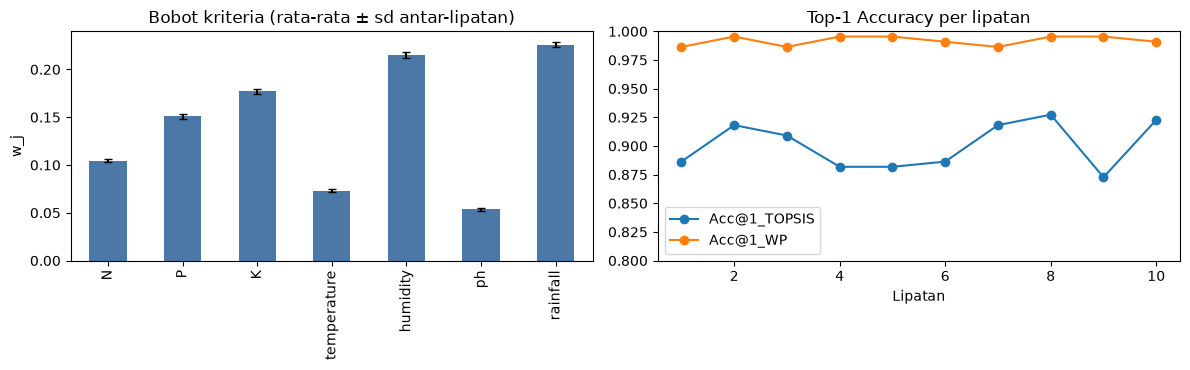

In [10]:
# Bobot Random Forest tiap lipatan (Pers. 3)
BOBOT_FOLD = pd.DataFrame({k: c['w'] for k, c in CACHE.items()}, index=FITUR).T
BOBOT_FOLD.index.name = 'Lipatan'
display(BOBOT_FOLD)
print('Jumlah bobot tiap lipatan:', BOBOT_FOLD.sum(axis=1).round(12).unique())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
BOBOT_FOLD.mean().plot.bar(yerr=BOBOT_FOLD.std(ddof=1), ax=ax[0], capsize=3, color='#4c78a8')
ax[0].set_title('Bobot kriteria (rata-rata ± sd antar-lipatan)'); ax[0].set_ylabel('w_j')
HASIL_S0[['Acc@1_TOPSIS', 'Acc@1_WP']].plot(marker='o', ax=ax[1]); ax[1].set_ylim(0.8, 1.0)
ax[1].set_title('Top-1 Accuracy per lipatan'); plt.tight_layout(); plt.show()

### 8.1 Verifikasi klaim subbab 2.6 — Fuzzy WP ≡ jarak-z kuadrat berbobot

Karena $\ln S_{ij} = -z_{ij}^2/2$, urutan Fuzzy WP seharusnya sama dengan urutan jarak-z kuadrat berbobot (naik). Perbedaan hanya mungkin muncul bila $S_{ij}$ sangat kecil sehingga $\varepsilon = 10^{-9}$ ikut berpengaruh.

In [11]:
top1_sama = top3_sama = rn_sama = urut_sama = n_tot = 0
for k, c in CACHE.items():
    z2 = ((X[c['te']][:, None, :] - c['mu'][None]) / c['sd'][None]) ** 2
    jarak = (c['w'][None, None, :] * z2).sum(axis=2)
    L = fuzzy_wp_ln(c['S'], c['w'])
    oJ, oL = np.argsort(jarak, axis=1, kind='stable'), np.argsort(-L, axis=1, kind='stable')
    yi = Y_IDX[c['te']]
    top1_sama += int((oJ[:, 0] == oL[:, 0]).sum())
    top3_sama += int((oJ[:, :3] == oL[:, :3]).all(axis=1).sum())
    rn_sama   += int((peringkat_benar(-jarak, yi) == peringkat_benar(L, yi)).sum())
    urut_sama += int((oJ == oL).all(axis=1).sum())
    n_tot += len(L)
print(f'Top-1 identik                    : {top1_sama}/{n_tot} ({top1_sama/n_tot:.2%})')
print(f'Top-3 (urutan) identik           : {top3_sama}/{n_tot} ({top3_sama/n_tot:.2%})')
print(f'Peringkat tanaman benar identik  : {rn_sama}/{n_tot} ({rn_sama/n_tot:.2%})')
print(f'Seluruh 22 urutan identik        : {urut_sama}/{n_tot} ({urut_sama/n_tot:.2%})')

Top-1 identik                    : 2200/2200 (100.00%)
Top-3 (urutan) identik           : 1296/2200 (58.91%)
Peringkat tanaman benar identik  : 2200/2200 (100.00%)
Seluruh 22 urutan identik        : 0/2200 (0.00%)


## 9. Analisis sensitivitas bobot (Tabel 4)

* **S0** — Gini feature importance (pengaturan utama)
* **S1** — bobot sama (1/7)
* **S2** — permutation importance (`ASUMSI`: dihitung pada data latih lipatan, nilai negatif di-clip ke 0, lalu dinormalisasi)
* **S3** — perturbasi acak ±20% pada bobot S0, 100 pengulangan, dinormalisasi ulang

In [12]:
# S2: permutation importance per lipatan
W_PERM = {}
for k, c in CACHE.items():
    pi = permutation_importance(c['rf'], X[c['tr']], Y_ENC[c['tr']], n_repeats=N_PERM_REPEAT,
                                random_state=SEED, n_jobs=-1)
    imp = np.clip(pi.importances_mean, 0, None)
    W_PERM[k] = imp / imp.sum()

HASIL_S1, _, _ = evaluasi_skema(lambda k: np.full(7, 1 / 7))
HASIL_S2, _, _ = evaluasi_skema(lambda k: W_PERM[k])

# S3: perturbasi acak
rng = np.random.default_rng(SEED)
acc1T = np.zeros((N_PERTURB, N_FOLD)); acc1W = np.zeros_like(acc1T)
stabT = np.zeros_like(acc1T);          stabW = np.zeros_like(acc1T)
for k, c in CACHE.items():
    S, yi, w0 = c['S'], Y_IDX[c['te']], c['w']
    t0, w0top = topsis(S, w0).argmax(1), fuzzy_wp_ln(S, w0).argmax(1)
    for r in range(N_PERTURB):
        wp_ = w0 * rng.uniform(0.8, 1.2, size=7); wp_ /= wp_.sum()
        V, L = topsis(S, wp_), fuzzy_wp_ln(S, wp_)
        acc1T[r, k-1] = np.mean(V.argmax(1) == yi); acc1W[r, k-1] = np.mean(L.argmax(1) == yi)
        stabT[r, k-1] = np.mean(V.argmax(1) == t0);  stabW[r, k-1] = np.mean(L.argmax(1) == w0top)
a1T, a1W = acc1T.mean(axis=1), acc1W.mean(axis=1)

def baris(nama, h):
    return {'Skenario': nama, 'Acc@1 TOPSIS': h['Acc@1_TOPSIS'].mean(), 'Acc@1 WP': h['Acc@1_WP'].mean(),
            'Acc@3 TOPSIS': h['Acc@3_TOPSIS'].mean(), 'Acc@3 WP': h['Acc@3_WP'].mean(),
            'MR TOPSIS': h['MR_TOPSIS'].mean(), 'MR WP': h['MR_WP'].mean(), 'Agr': h['Agr'].mean()}
SENS = pd.DataFrame([baris('S0 Gini', HASIL_S0), baris('S1 bobot sama', HASIL_S1), baris('S2 permutation', HASIL_S2)])
S3 = {'Skenario': 'S3 perturbasi ±20% (rata-rata 100 pengulangan)',
      'Acc@1 TOPSIS': a1T.mean(), 'Acc@1 WP': a1W.mean()}
SENS = pd.concat([SENS, pd.DataFrame([S3])], ignore_index=True)
display(SENS)
print(f'S3 — simpangan baku antar-pengulangan Acc@1: TOPSIS {a1T.std(ddof=1):.5f} | WP {a1W.std(ddof=1):.5f}')
print(f'S3 — rentang Acc@1: TOPSIS [{a1T.min():.4f}, {a1T.max():.4f}] | WP [{a1W.min():.4f}, {a1W.max():.4f}]')
print(f'S3 — kestabilan top-1 terhadap S0: TOPSIS {stabT.mean():.2%} | WP {stabW.mean():.2%}')
display(pd.DataFrame(W_PERM, index=FITUR).T.rename_axis('Lipatan').assign(jumlah=lambda d: d.sum(axis=1)))

,Skenario,Acc@1 TOPSIS,Acc@1 WP,Acc@3 TOPSIS,Acc@3 WP,MR TOPSIS,MR WP,Agr
0,S0 Gini,0.900455,0.991818,0.995000,1.000000,1.126364,1.008182,0.906364
1,S1 bobot sama,0.953636,0.990000,0.999091,1.000000,1.052727,1.010000,0.959091
2,S2 permutation,0.792727,0.984545,0.969545,1.000000,1.305909,1.015455,0.804091
3,S3 perturbasi ±20% (rata-rata 100 pengulangan),0.892327,0.991655,NaN,NaN,NaN,NaN,NaN


S3 — simpangan baku antar-pengulangan Acc@1: TOPSIS 0.00746 | WP 0.00039
S3 — rentang Acc@1: TOPSIS [0.8682, 0.9100] | WP [0.9909, 0.9923]
S3 — kestabilan top-1 terhadap S0: TOPSIS 96.29% | WP 99.95%


,N,P,K,temperature,humidity,ph,rainfall,jumlah
Lipatan,,,,,,,,
1,0.169588,0.145758,0.145865,0.008015,0.321436,0.008121,0.201218,1.000000
2,0.180263,0.119550,0.171763,0.006071,0.322000,0.010487,0.189866,1.000000
3,0.223349,0.125176,0.171050,0.007328,0.280165,0.007227,0.185706,1.000000
4,0.180296,0.133218,0.178267,0.004566,0.311993,0.009740,0.181920,1.000000
5,0.190185,0.141499,0.171079,0.004364,0.313161,0.008244,0.171467,1.000000
6,0.203507,0.121820,0.143610,0.004561,0.298774,0.008108,0.219621,1.000000
7,0.203860,0.122905,0.137329,0.005180,0.314982,0.007313,0.208431,1.000000
8,0.177573,0.129071,0.171260,0.006514,0.309450,0.009219,0.196914,1.000000
9,0.231172,0.114920,0.165667,0.004570,0.288965,0.004570,0.190136,1.000000


## 10. Studi kasus — 5 teratas format dosen & pembanding manual (Excel)

Lima kasus uji diambil dari **data uji lipatan 1** (`ID = 10, 43, 311, 722, 2102`) ditambah satu **Kasus_Sistem** (input tanah + cuaca agregat Bagian 3).
Sesuai arahan dosen, setiap kasus menampilkan **5 peringkat teratas** dengan kolom:
`No | Nama Tanaman (Alternatif) | Nilai Vi | Peringkat Manual | Peringkat Sistem | Keterangan`

*Catatan:* `Peringkat Sistem` diisi dengan hasil uji dari aplikasi web Laravel (atau disimulasikan dengan fungsi sistem yang identik di sini untuk verifikasi awal), dan `Rekomendasi Utama` ditetapkan dari **Peringkat 1 Fuzzy WP** disertai status kesepakatan dengan TOPSIS.

In [13]:
KASUS_ID = [10, 43, 311, 722, 2102]                 # nomor baris data (1-based)
c1 = CACHE[1]
w_L1, mu_L1, sd_L1 = c1['w'], c1['mu'], c1['sd']
w_ALL, _ = bobot_rf(X, Y_ENC)                       # kasus sistem: seluruh dataset
mu_ALL, sd_ALL = profil_tanaman(X, Y_IDX)

print('Bobot S0 lipatan 1      :', np.round(w_L1, 6))
print('Bobot S0 seluruh data   :', np.round(w_ALL, 6))
assert all(FOLD[i - 1] == 1 for i in KASUS_ID), 'kasus harus berasal dari data uji lipatan 1'

def hitung_kasus(x, mu, sd, w, nama):
    S = kesesuaian_gaussian(x, mu, sd)
    V, d = topsis(S, w, detail=True); L = fuzzy_wp_ln(S, w)
    rT = 1 + (V[0][None, :] > V[0][:, None]).sum(axis=1)
    rW = 1 + (L[0][None, :] > L[0][:, None]).sum(axis=1)
    tab = pd.DataFrame({'Kasus': nama, 'Kode': KODE, 'Tanaman': KELAS,
                        'Tanaman_ID': [f"{NAMA_ID[k]} ({k})" for k in KELAS],
                        **{f'S_{f}': S[0][:, j] for j, f in enumerate(FITUR)},
                        'D+': d['Dp'][0], 'D-': d['Dm'][0], 'V_TOPSIS': V[0], 'Rank_TOPSIS': rT,
                        'lnP': L[0], 'P_WP': np.exp(L[0]), 'Rank_WP': rW})
    return tab

HASIL_KASUS, RINGKAS = [], []
for i, idx in enumerate(KASUS_ID, start=1):
    x = X[idx - 1][None, :]
    tab = hitung_kasus(x, mu_L1, sd_L1, w_L1, f'Kasus_{i}')
    HASIL_KASUS.append(tab)
    ben = df.loc[idx - 1, 'label']
    top1_T = tab.loc[tab.V_TOPSIS.idxmax(), 'Tanaman']
    top1_W = tab.loc[tab.lnP.idxmax(), 'Tanaman']
    RINGKAS.append({
        'Kasus': f'Kasus_{i}', 'ID': idx, 'Tanaman benar': ben,
        'Rank TOPSIS (benar)': int(tab.loc[tab.Tanaman == ben, 'Rank_TOPSIS'].iloc[0]),
        'Rank WP (benar)': int(tab.loc[tab.Tanaman == ben, 'Rank_WP'].iloc[0]),
        'Top-1 TOPSIS': top1_T, 'Top-1 WP (Utama)': top1_W,
        'Status Metode': 'Sepakat' if top1_T == top1_W else 'Berbeda'
    })

# Kasus sistem: N, P, K, pH dari pengguna + cuaca agregat (Pers. 1-2)
N_IN, P_IN, K_IN, PH_IN = 90, 42, 43, 6.5
x_sis = np.array([[N_IN, P_IN, K_IN, SUHU_AGG, LEMBAP_AGG, PH_IN, HUJAN_AGG]])
tab_sis = hitung_kasus(x_sis, mu_ALL, sd_ALL, w_ALL, 'Kasus_Sistem')
HASIL_KASUS.append(tab_sis)
top1_T_sis = tab_sis.loc[tab_sis.V_TOPSIS.idxmax(), 'Tanaman']
top1_W_sis = tab_sis.loc[tab_sis.lnP.idxmax(), 'Tanaman']
RINGKAS.append({
    'Kasus': 'Kasus_Sistem', 'ID': '-', 'Tanaman benar': '-', 'Rank TOPSIS (benar)': '-', 'Rank WP (benar)': '-',
    'Top-1 TOPSIS': top1_T_sis, 'Top-1 WP (Utama)': top1_W_sis,
    'Status Metode': 'Sepakat' if top1_T_sis == top1_W_sis else 'Berbeda'
})
display(pd.DataFrame(RINGKAS))

Bobot S0 lipatan 1      : [0.104747 0.156182 0.172621 0.073533 0.217594 0.053303 0.222021]
Bobot S0 seluruh data   : [0.103244 0.150277 0.177599 0.073691 0.216988 0.052671 0.22553 ]


,Kasus,ID,Tanaman benar,Rank TOPSIS (benar),Rank WP (benar),Top-1 TOPSIS,Top-1 WP (Utama),Status Metode
0,Kasus_1,10,rice,1,1,rice,rice,Sepakat
1,Kasus_2,43,rice,2,2,jute,jute,Sepakat
2,Kasus_3,311,kidneybeans,2,1,chickpea,kidneybeans,Berbeda
3,Kasus_4,722,blackgram,8,1,maize,blackgram,Berbeda
4,Kasus_5,2102,coffee,1,1,coffee,coffee,Sepakat
5,Kasus_Sistem,-,-,-,-,jute,jute,Sepakat


In [14]:
# Tabel 5 Teratas Format Arahan Dosen (untuk verifikasi Manual vs Sistem Laravel)
# Isi kolom 'Peringkat Sistem' dengan hasil aktual dari web Laravel saat pengujian
def buat_tabel_top5_dosen(tab, metode='TOPSIS', peringkat_sistem=None):
    if metode == 'TOPSIS':
        sub = tab.sort_values(['Rank_TOPSIS', 'V_TOPSIS'], ascending=[True, False]).head(5).reset_index(drop=True)
        nilai_col, rank_col = 'V_TOPSIS', 'Rank_TOPSIS'
        nama_nilai = 'Nilai Vi'
    else:
        sub = tab.sort_values(['Rank_WP', 'P_WP'], ascending=[True, False]).head(5).reset_index(drop=True)
        nilai_col, rank_col = 'P_WP', 'Rank_WP'
        nama_nilai = 'Nilai Pi (Fuzzy WP)'

    p_sys = list(sub[rank_col]) if peringkat_sistem is None else peringkat_sistem
    ket = ['Sesuai' if int(m) == int(s) else 'Tidak sesuai' for m, s in zip(sub[rank_col], p_sys)]
    return pd.DataFrame({
        'No': np.arange(1, 6),
        'Nama Tanaman (Alternatif)': sub['Kode'] + ' - ' + sub['Tanaman_ID'],
        nama_nilai: sub[nilai_col],
        'Peringkat Manual': sub[rank_col],
        'Peringkat Sistem': p_sys,
        'Keterangan': ket
    })

TOP5_TOPSIS_ALL, TOP5_WP_ALL = [], []
for tab in HASIL_KASUS:
    nama_kasus = tab['Kasus'].iloc[0]
    t5_T = buat_tabel_top5_dosen(tab, 'TOPSIS')
    t5_W = buat_tabel_top5_dosen(tab, 'WP')
    TOP5_TOPSIS_ALL.append(t5_T.assign(Kasus=nama_kasus))
    TOP5_WP_ALL.append(t5_W.assign(Kasus=nama_kasus))
    print(f'=== {nama_kasus} — 5 Teratas TOPSIS (Format Dosen) ===')
    display(t5_T)
    print(f'=== {nama_kasus} — 5 Teratas Fuzzy WP (Format Dosen) ===')
    display(t5_W)

=== Kasus_1 — 5 Teratas TOPSIS (Format Dosen) ===


,No,Nama Tanaman (Alternatif),Nilai Vi,Peringkat Manual,Peringkat Sistem,Keterangan
0,1,A1 - Padi (rice),0.802816,1,1,Sesuai
1,2,A21 - Rami (jute),0.434912,2,2,Sesuai
2,3,A18 - Pepaya (papaya),0.434771,3,3,Sesuai
3,4,A10 - Delima (pomegranate),0.290246,4,4,Sesuai
4,5,A14 - Semangka (watermelon),0.268530,5,5,Sesuai


=== Kasus_1 — 5 Teratas Fuzzy WP (Format Dosen) ===


,No,Nama Tanaman (Alternatif),Nilai Pi (Fuzzy WP),Peringkat Manual,Peringkat Sistem,Keterangan
0,1,A1 - Padi (rice),0.734565,1,1,Sesuai
1,2,A21 - Rami (jute),0.237296,2,2,Sesuai
2,3,A22 - Kopi (coffee),0.008637,3,3,Sesuai
3,4,A5 - Kacang gude (pigeonpeas),0.002484,4,4,Sesuai
4,5,A19 - Kelapa (coconut),0.002464,5,5,Sesuai


=== Kasus_2 — 5 Teratas TOPSIS (Format Dosen) ===


,No,Nama Tanaman (Alternatif),Nilai Vi,Peringkat Manual,Peringkat Sistem,Keterangan
0,1,A21 - Rami (jute),0.605533,1,1,Sesuai
1,2,A1 - Padi (rice),0.588835,2,2,Sesuai
2,3,A18 - Pepaya (papaya),0.468564,3,3,Sesuai
3,4,A19 - Kelapa (coconut),0.443163,4,4,Sesuai
4,5,A20 - Kapas (cotton),0.392769,5,5,Sesuai


... (14 outputs left out)

=== Kasus_Sistem — 5 Teratas TOPSIS (Format Dosen) ===


,No,Nama Tanaman (Alternatif),Nilai Vi,Peringkat Manual,Peringkat Sistem,Keterangan
0,1,A21 - Rami (jute),0.787439,1,1,Sesuai
1,2,A20 - Kapas (cotton),0.442881,2,2,Sesuai
2,3,A22 - Kopi (coffee),0.381035,3,3,Sesuai
3,4,A1 - Padi (rice),0.379947,4,4,Sesuai
4,5,A11 - Pisang (banana),0.364190,5,5,Sesuai


=== Kasus_Sistem — 5 Teratas Fuzzy WP (Format Dosen) ===


,No,Nama Tanaman (Alternatif),Nilai Pi (Fuzzy WP),Peringkat Manual,Peringkat Sistem,Keterangan
0,1,A21 - Rami (jute),0.556520,1,1,Sesuai
1,2,A1 - Padi (rice),0.088336,2,2,Sesuai
2,3,A22 - Kopi (coffee),0.055419,3,3,Sesuai
3,4,A18 - Pepaya (papaya),0.002339,4,4,Sesuai
4,5,A11 - Pisang (banana),0.001642,5,5,Sesuai


## 11. Uji fungsional otomatis (Tabel 5, butir 6 & 12–15)

Memeriksa sifat keluaran perhitungan yang diuji pada *black box testing* artikel, termasuk skenario masukan di luar rentang dataset (`K = 300`, butir 6).

In [15]:
# Uji khusus Skenario 6 Tabel 5: input valid di luar rentang dataset (mis. K = 300)
x_ekstrem = np.array([[90, 42, 300, SUHU_AGG, LEMBAP_AGG, 6.5, HUJAN_AGG]])
S_eks = kesesuaian_gaussian(x_ekstrem, mu_ALL, sd_ALL)
V_eks = topsis(S_eks, w_ALL)
L_eks = fuzzy_wp_ln(S_eks, w_ALL)

uji = []
def cek(no, fitur, skenario, kondisi):
    uji.append({'No': no, 'Fitur': fitur, 'Skenario Uji': skenario, 'Hasil': 'Sesuai' if kondisi else 'Tidak sesuai'})

cek(6,  'Rentang dataset', 'Input K = 300 (di luar rentang) tetap menghasilkan skor valid (bebas NaN)',
    (not np.isnan(V_eks).any()) and (not np.isnan(L_eks).any()) and np.all((V_eks >= 0) & (V_eks <= 1)))
cek(12, 'Pembobotan', 'Jumlah seluruh bobot = 1 (semua lipatan & kasus sistem)',
    np.allclose(BOBOT_FOLD.sum(axis=1), 1) and np.isclose(w_ALL.sum(), 1))
cek(13, 'TOPSIS', 'V_i dalam [0,1] dan 22 tanaman terurut menurun',
    all(t['V_TOPSIS'].between(0, 1).all() and len(t) == 22 and
        t.sort_values('V_TOPSIS', ascending=False)['Rank_TOPSIS'].is_monotonic_increasing for t in HASIL_KASUS))
cek(14, 'Fuzzy WP', '22 tanaman terurut menurun berdasarkan P_i',
    all(len(t) == 22 and t.sort_values('P_WP', ascending=False)['Rank_WP'].is_monotonic_increasing for t in HASIL_KASUS))
cek(15, 'Rekomendasi', 'Tanaman peringkat 1 Fuzzy WP menjadi rekomendasi utama beserta status kesepakatan TOPSIS',
    all(t.loc[t['Rank_WP'] == 1, 'Tanaman'].iloc[0] == t.loc[t['lnP'].idxmax(), 'Tanaman'] for t in HASIL_KASUS))
tabel_uji = pd.DataFrame(uji); display(tabel_uji)
print(f"Keberhasilan (Pers. 16): {(tabel_uji['Hasil'] == 'Sesuai').mean():.0%}")

,No,Fitur,Skenario Uji,Hasil
0,6,Rentang dataset,Input K = 300 (di luar rentang) tetap menghasi...,Sesuai
1,12,Pembobotan,Jumlah seluruh bobot = 1 (semua lipatan & kasu...,Sesuai
2,13,TOPSIS,"V_i dalam [0,1] dan 22 tanaman terurut menurun",Sesuai
3,14,Fuzzy WP,22 tanaman terurut menurun berdasarkan P_i,Sesuai
4,15,Rekomendasi,Tanaman peringkat 1 Fuzzy WP menjadi rekomenda...,Sesuai


Keberhasilan (Pers. 16): 100%


## 12. Ekspor parameter model & acuan uji ke JSON/Excel (Integrasi Laravel)

Sel ini mengekspor:
1. `model_params.json` — bobot global `w_ALL`, profil $\mu_{ij}, \sigma_{ij}$ 22 tanaman, rentang dataset Tabel 1, dan konstanta (`SIGMA_ADD`, `EPS`, `WINDOW_N`, `WINDOW_M`).
2. `test_cases_reference.json` — 6 kasus uji (termasuk `Kasus_Sistem`) beserta hasil eksak `V_TOPSIS`, `Rank_TOPSIS`, `lnP`, `P_WP`, `Rank_WP` untuk *unit test* PHPUnit di Laravel.
3. `hasil_model_perbandingan.csv` & `hasil_model_kasus.xlsx` (termasuk sheet `Top5_TOPSIS_Dosen` dan `Top5_WP_Dosen`).

In [16]:
# 1. Ekspor model_params.json untuk backend Laravel
model_params = {
    'metadata': {
        'dataset_rows': int(len(df)),
        'n_crops': int(len(KELAS)),
        'n_trees': N_TREES,
        'seed': SEED,
        'sigma_add': SIGMA_ADD,
        'eps': EPS,
        'window_n': WINDOW_N,
        'window_m': WINDOW_M
    },
    'features': FITUR,
    'weights': {f: float(w) for f, w in zip(FITUR, w_ALL)},
    'dataset_ranges': {
        f: {'min': float(df[f].min()), 'max': float(df[f].max())} for f in FITUR
    },
    'crops': [
        {
            'kode': KODE[i],
            'label': KELAS[i],
            'nama_id': NAMA_ID[KELAS[i]],
            'mu': {f: float(mu_ALL[i, j]) for j, f in enumerate(FITUR)},
            'sd': {f: float(sd_ALL[i, j]) for j, f in enumerate(FITUR)}  # sudah termasuk + SIGMA_ADD
        }
        for i in range(len(KELAS))
    ]
}
with open('model_params.json', 'w', encoding='utf-8') as f:
    json.dump(model_params, f, indent=2, ensure_ascii=False)

# 2. Ekspor test_cases_reference.json untuk verifikasi PHPUnit di Laravel
test_refs = []
for tab in HASIL_KASUS:
    nama = tab['Kasus'].iloc[0]
    if nama == 'Kasus_Sistem':
        inp = dict(zip(FITUR, [float(v) for v in x_sis[0]]))
    else:
        idx_baris = KASUS_ID[int(nama.split('_')[1]) - 1] - 1
        inp = dict(zip(FITUR, [float(v) for v in X[idx_baris]]))
    test_refs.append({
        'kasus': nama,
        'input': inp,
        'rekomendasi_utama_wp': tab.loc[tab['Rank_WP'] == 1, 'Tanaman'].iloc[0],
        'top1_topsis': tab.loc[tab['Rank_TOPSIS'] == 1, 'Tanaman'].iloc[0],
        'top5_topsis': tab.sort_values('Rank_TOPSIS').head(5)[['Kode', 'Tanaman', 'V_TOPSIS', 'Rank_TOPSIS']].to_dict('records'),
        'top5_wp': tab.sort_values('Rank_WP').head(5)[['Kode', 'Tanaman', 'P_WP', 'lnP', 'Rank_WP']].to_dict('records')
    })
with open('test_cases_reference.json', 'w', encoding='utf-8') as f:
    json.dump(test_refs, f, indent=2, ensure_ascii=False)

# 3. Ekspor CSV & Excel lengkap dengan sheet format dosen
PERBANDINGAN = pd.concat([t[['Kasus', 'Kode', 'Tanaman', 'V_TOPSIS', 'Rank_TOPSIS', 'lnP', 'P_WP', 'Rank_WP']] for t in HASIL_KASUS],
                         ignore_index=True)
PERBANDINGAN.to_csv('hasil_model_perbandingan.csv', index=False)

with pd.ExcelWriter('hasil_model_kasus.xlsx') as xw:
    pd.DataFrame(RINGKAS).to_excel(xw, sheet_name='Ringkasan', index=False)
    pd.concat(TOP5_TOPSIS_ALL, ignore_index=True).to_excel(xw, sheet_name='Top5_TOPSIS_Dosen', index=False)
    pd.concat(TOP5_WP_ALL, ignore_index=True).to_excel(xw, sheet_name='Top5_WP_Dosen', index=False)
    for tab in HASIL_KASUS:
        tab.drop(columns='Kasus').to_excel(xw, sheet_name=tab['Kasus'].iloc[0], index=False)
    HASIL_S0.reset_index().to_excel(xw, sheet_name='CV_per_lipatan_S0', index=False)
    BOBOT_FOLD.reset_index().to_excel(xw, sheet_name='Bobot_per_lipatan', index=False)
    SENS.to_excel(xw, sheet_name='Sensitivitas', index=False)
print('Tersimpan: model_params.json, test_cases_reference.json, hasil_model_perbandingan.csv, hasil_model_kasus.xlsx')

Tersimpan: model_params.json, test_cases_reference.json, hasil_model_perbandingan.csv, hasil_model_kasus.xlsx
